COMPARAÇÃO DOS EXTREMOS
Centroide + triângulos   : mínimo=8.33% | máximo=91.67%
Centroide + trapézio     : mínimo=8.33% | máximo=90.71%
MOM + trapézio           : mínimo=0.00% | máximo=95.00%
Híbrido + trapézio       : mínimo=0.00% | máximo=100.00%


/tmp/ipykernel_507/813194151.py:12: RuntimeWarning: invalid value encountered in scalar divide
  return np.maximum(0, np.minimum(np.where(b==a, 1.0, (v-a)/(b-a)), np.where(c==b, 1.0, (c-v)/(c-b))))
/tmp/ipykernel_507/813194151.py:12: RuntimeWarning: divide by zero encountered in scalar divide
  return np.maximum(0, np.minimum(np.where(b==a, 1.0, (v-a)/(b-a)), np.where(c==b, 1.0, (c-v)/(c-b))))
/tmp/ipykernel_507/813194151.py:12: RuntimeWarning: divide by zero encountered in divide
  return np.maximum(0, np.minimum(np.where(b==a, 1.0, (v-a)/(b-a)), np.where(c==b, 1.0, (c-v)/(c-b))))
/tmp/ipykernel_507/813194151.py:12: RuntimeWarning: invalid value encountered in divide
  return np.maximum(0, np.minimum(np.where(b==a, 1.0, (v-a)/(b-a)), np.where(c==b, 1.0, (c-v)/(c-b))))


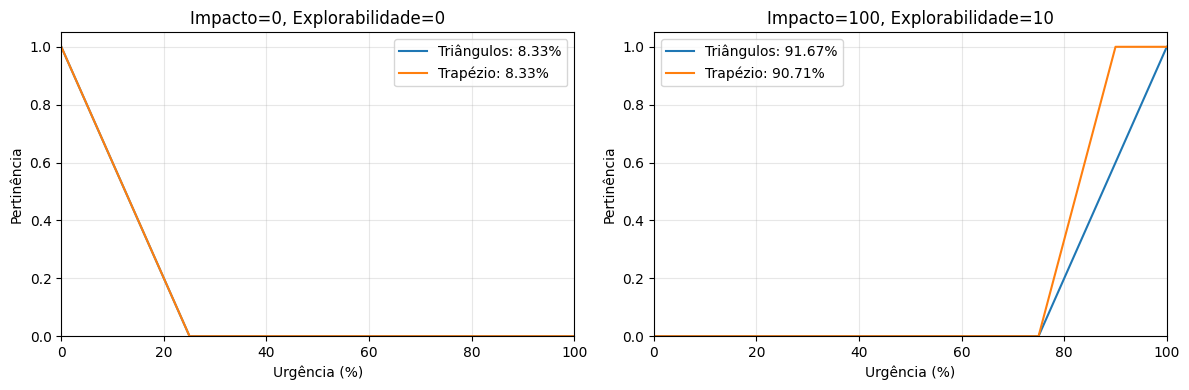

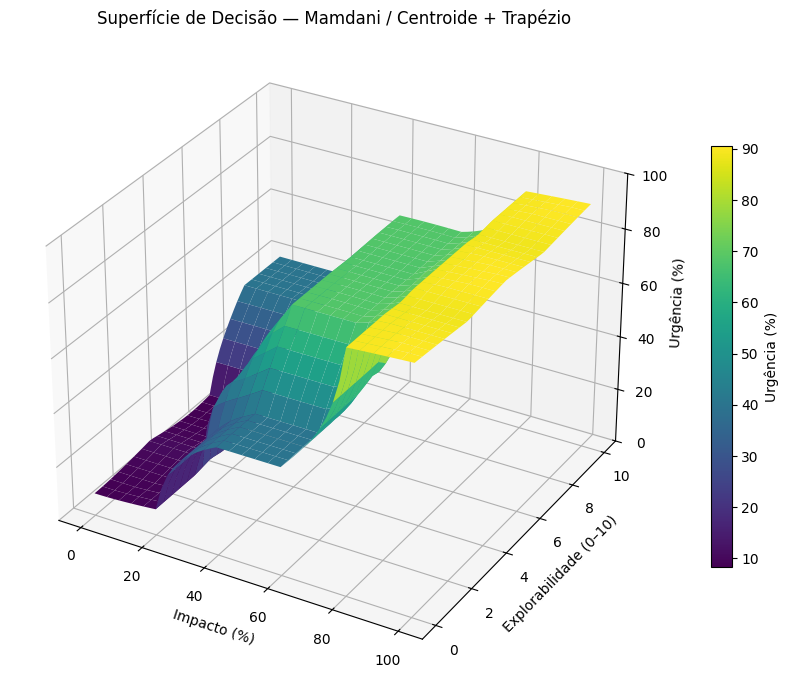

Arquivos criados em /content/AULA_10


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from zipfile import ZipFile

PASTA = Path('AULA_10')
PASTA.mkdir(exist_ok=True)
x = np.linspace(0, 100, 1001)

def trimf(v, abc):
    a,b,c=abc
    return np.maximum(0, np.minimum(np.where(b==a, 1.0, (v-a)/(b-a)), np.where(c==b, 1.0, (c-v)/(c-b))))

def trapmf(v, abcd):
    a,b,c,d=abcd
    left = np.ones_like(np.asarray(v,dtype=float)) if a==b else np.clip((v-a)/(b-a),0,1)
    right = np.ones_like(np.asarray(v,dtype=float)) if c==d else np.clip((d-v)/(d-c),0,1)
    return np.minimum(left,right)

def pertinencias(i,e):
    return [trimf(np.asarray(i),[0,0,40]),trimf(np.asarray(i),[20,50,80]),trimf(np.asarray(i),[60,100,100])], [trimf(np.asarray(e),[0,0,4]),trimf(np.asarray(e),[2,5,8]),trimf(np.asarray(e),[6,10,10])]

regras = [[0,0,1],[1,2,2],[3,3,3]]
nomes=['Baixa','Média','Alta','Crítica']

def calcular(i,e,metodo='centroid',trapezio=False,hibrido=False):
    mi,me=pertinencias(i,e)
    saidas=[trimf(x,[0,0,25]),trimf(x,[15,40,65]),trimf(x,[45,70,90]),trapmf(x,[75,90,100,100]) if trapezio else trimf(x,[75,100,100])]
    agregado=np.zeros_like(x)
    for a in range(3):
        for b in range(3):
            agregado=np.maximum(agregado,np.minimum(min(float(mi[a]),float(me[b])),saidas[regras[a][b]]))
    if agregado.max()==0: raise ValueError('Nenhuma regra ativada')
    if metodo=='mom': resultado=float(np.mean(x[np.isclose(agregado,agregado.max(),atol=1e-10)]))
    else: resultado=float(np.trapezoid(x*agregado,x)/np.trapezoid(agregado,x))
    if hibrido and i==0 and e==0: resultado=0.0
    if hibrido and i==100 and e==10: resultado=100.0
    return resultado,agregado

print('COMPARAÇÃO DOS EXTREMOS')
for nome,kw in [('Centroide + triângulos',{}),('Centroide + trapézio',{'trapezio':True}),('MOM + trapézio',{'metodo':'mom','trapezio':True}),('Híbrido + trapézio',{'trapezio':True,'hibrido':True})]:
    print(f'{nome:25s}: mínimo={calcular(0,0,**kw)[0]:.2f}% | máximo={calcular(100,10,**kw)[0]:.2f}%')

fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,(i,e) in zip(axs,[(0,0),(100,10)]):
    for nome,kw in [('Triângulos',{}),('Trapézio',{'trapezio':True})]:
        valor,ag=calcular(i,e,**kw)
        ax.plot(x,ag,label=f'{nome}: {valor:.2f}%')
    ax.set(title=f'Impacto={i}, Explorabilidade={e}',xlabel='Urgência (%)',ylabel='Pertinência',xlim=(0,100),ylim=(0,1.05))
    ax.grid(alpha=.3);ax.legend()
plt.tight_layout();plt.savefig(PASTA/'extremos_comparacao.png',dpi=180);plt.show()

impactos=np.linspace(0,100,51)
explorabilidades=np.linspace(0,10,51)
I,E=np.meshgrid(impactos,explorabilidades)
Z=np.empty_like(I)
for idx in np.ndindex(I.shape):
    Z[idx]=calcular(float(I[idx]),float(E[idx]),trapezio=True)[0]
fig=plt.figure(figsize=(11,7))
ax=fig.add_subplot(111,projection='3d')
surf=ax.plot_surface(I,E,Z,cmap='viridis',linewidth=0,antialiased=True)
ax.set(xlabel='Impacto (%)',ylabel='Explorabilidade (0–10)',zlabel='Urgência (%)',title='Superfície de Decisão — Mamdani / Centroide + Trapézio',zlim=(0,100))
fig.colorbar(surf,ax=ax,shrink=.65,label='Urgência (%)')
plt.tight_layout();plt.savefig(PASTA/'superficie_decisao.png',dpi=200);plt.show()

min_base=calcular(0,0)[0];max_base=calcular(100,10)[0]
min_trap=calcular(0,0,trapezio=True)[0];max_trap=calcular(100,10,trapezio=True)[0]
min_mom=calcular(0,0,metodo='mom',trapezio=True)[0];max_mom=calcular(100,10,metodo='mom',trapezio=True)[0]
relatorio=f'''# Aula 10 — Motor de Inferência Mamdani

## Desafio dos extremos

O Centroide calcula o centro de massa da área agregada, pela razão entre o primeiro momento e a área. Mesmo quando uma função triangular tem pico em 0 ou 100, sua área se estende para dentro do universo; logo, o centro de massa não coincide com a ponta. Os valores dependem das funções de pertinência escolhidas: os 4,33% e 87,5% do enunciado são exemplos de outra parametrização.

| Configuração | (0, 0) | (100, 10) |
|---|---:|---:|
| Centroide + triângulos | {min_base:.2f}% | {max_base:.2f}% |
| Centroide + trapézio crítico | {min_trap:.2f}% | {max_trap:.2f}% |
| MOM + trapézio crítico | {min_mom:.2f}% | {max_mom:.2f}% |
| Híbrido (centroide + tratamento dos extremos exatos) | 0,00% | 100,00% |

O trapézio crítico amplia a região de pertinência máxima, mas o Centroide continua calculando uma média ponderada da área, sem necessariamente alcançar 100%. O MOM calcula a média dos pontos em que a pertinência agregada é máxima; pode atingir uma ponta quando o máximo é pontual nela, mas em um platô retorna o ponto médio do platô. Pode introduzir saltos na saída quando o conjunto de máximos muda. O tratamento híbrido força os dois pontos extremos exatos, mas **não garante continuidade matemática nas vizinhanças desses pontos**. Para suavidade rigorosa até os extremos, seria necessário redesenhar o sistema ou empregar outra transformação contínua da saída.

## Matriz 3×3

| Impacto \\ Explorabilidade | Baixa | Moderada | Alta |
|---|---|---|---|
| Baixo | Urgência Baixa | Urgência Baixa | Urgência Média |
| Médio | Urgência Média | Urgência Alta | Urgência Alta |
| Alto | Urgência Crítica | Urgência Crítica | Urgência Crítica |

## Análise da superfície 3D

A superfície representa o mapeamento de Impacto e Explorabilidade para Urgência. Impactos altos ativam regras críticas independentemente da explorabilidade. Impactos médios tendem a urgências maiores quando a explorabilidade aumenta. As sobreposições entre conjuntos fuzzy permitem interpolação gradual na maior parte da escala, sem lacunas de regras. A superfície plotada usa Centroide + Trapézio e não aplica correção pontual; portanto representa a resposta contínua do motor, sem afirmar que chega a 0% ou 100%.

## Parâmetros reproduzíveis

Impacto: baixo [0,0,40], médio [20,50,80], alto [60,100,100]. Explorabilidade: baixa [0,0,4], moderada [2,5,8], alta [6,10,10]. Saída: baixa [0,0,25], média [15,40,65], alta [45,70,90], crítica triangular [75,100,100] ou trapezoidal [75,90,100,100]. Inferência min/max; resolução da saída 0,1.
'''
(PASTA/'resultados_aula10.md').write_text(relatorio,encoding='utf-8')
print('Arquivos criados em',PASTA.resolve())